# Multi-Class Preprocessing Comparison for EfficientNet-B0

This notebook compares three `EfficientNet-B0` multi-class diabetic retinopathy grading experiments on the same APTOS 2019 test split:

- baseline without preprocessing;
- retinal crop preprocessing;
- retinal crop preprocessing with CLAHE.

The goal is to measure whether retinal-focused preprocessing improves class-wise severity grading and ordinal agreement.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    cohen_kappa_score,
    precision_recall_fscore_support,
    roc_auc_score,
)
from torch.utils.data import DataLoader

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)


In [2]:
project_root = Path.cwd().resolve()
for candidate in [project_root, *project_root.parents]:
    if (candidate / "src").exists() and (candidate / "configs").exists():
        project_root = candidate
        break

sys.path.insert(0, str(project_root / "src"))

from dr_detection.config import load_yaml_config, resolve_path
from dr_detection.dataset import FundusImageDataset, default_transforms, load_fundus_records
from dr_detection.train import build_model

comparison_dir = project_root / "outputs" / "multiclass_comparison"
comparison_dir.mkdir(parents=True, exist_ok=True)

class_labels = [0, 1, 2, 3, 4]
class_names = {
    0: "No DR",
    1: "Mild DR",
    2: "Moderate DR",
    3: "Severe DR",
    4: "Proliferative DR",
}

model_specs = [
    {
        "display_name": "Baseline",
        "short_name": "baseline",
        "column_name": "Baseline",
        "config_path": project_root / "configs" / "efficientnet_b0_multiclass.yaml",
    },
    {
        "display_name": "Crop",
        "short_name": "crop",
        "column_name": "Crop",
        "config_path": project_root / "configs" / "efficientnet_b0_multiclass_crop.yaml",
    },
    {
        "display_name": "Crop + CLAHE",
        "short_name": "crop_clahe",
        "column_name": "Crop + CLAHE",
        "config_path": project_root / "configs" / "efficientnet_b0_multiclass_crop_clahe.yaml",
    },
]

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"Comparison output directory: {comparison_dir}")
print(f"Device: {device}")


Comparison output directory: /Users/berekebaimuratov/Desktop/Detection of Diabetic Retinopathy/outputs/multiclass_comparison
Device: mps


In [3]:
def evaluate_model(spec: dict) -> tuple[dict, pd.DataFrame]:
    config = load_yaml_config(spec["config_path"])
    dataset_cfg = config["dataset"]
    training_cfg = config["training"]
    checkpoint_path = resolve_path(project_root, config["paths"]["model_dir"]) / "best_model.pt"

    test_records = load_fundus_records(
        csv_path=resolve_path(project_root, dataset_cfg["test_csv_path"]),
        images_dir=resolve_path(project_root, dataset_cfg["test_images_dir"]),
        image_extension=dataset_cfg.get("image_extension", ".png"),
        binary_classification=dataset_cfg.get("binary_classification", True),
    )

    test_dataset = FundusImageDataset(
        test_records,
        transform=default_transforms(
            image_size=dataset_cfg.get("image_size", 224),
            train=False,
            preprocessing_cfg=dataset_cfg.get("preprocessing"),
        ),
    )
    test_loader = DataLoader(
        test_dataset,
        batch_size=training_cfg.get("batch_size", 16),
        shuffle=False,
        num_workers=0,
    )

    checkpoint = torch.load(checkpoint_path, map_location=device)
    model = build_model(
        model_name=checkpoint["model_name"],
        num_classes=checkpoint["num_classes"],
        pretrained=False,
    )
    model.load_state_dict(checkpoint["model_state_dict"])
    model = model.to(device)
    model.eval()

    all_labels = []
    all_predictions = []
    all_probabilities = []

    with torch.no_grad():
        for images, labels, _ in test_loader:
            images = images.to(device)
            logits = model(images)
            probabilities = torch.softmax(logits, dim=1)
            predictions = probabilities.argmax(dim=1)

            all_labels.extend(labels.tolist())
            all_predictions.extend(predictions.cpu().tolist())
            all_probabilities.extend(probabilities.cpu().tolist())

    probability_array = np.asarray(all_probabilities, dtype=np.float32)
    macro_precision, macro_recall, macro_f1, _ = precision_recall_fscore_support(
        all_labels,
        all_predictions,
        labels=class_labels,
        average="macro",
        zero_division=0,
    )
    weighted_f1 = precision_recall_fscore_support(
        all_labels,
        all_predictions,
        labels=class_labels,
        average="weighted",
        zero_division=0,
    )[2]

    metrics = {
        "model": spec["display_name"],
        "accuracy": accuracy_score(all_labels, all_predictions),
        "precision_macro": macro_precision,
        "recall_macro": macro_recall,
        "f1_macro": macro_f1,
        "f1_weighted": weighted_f1,
        "qwk": cohen_kappa_score(all_labels, all_predictions, weights="quadratic"),
        "roc_auc_ovr_macro": roc_auc_score(
            all_labels,
            probability_array,
            labels=class_labels,
            multi_class="ovr",
            average="macro",
        ),
        "roc_auc_ovr_weighted": roc_auc_score(
            all_labels,
            probability_array,
            labels=class_labels,
            multi_class="ovr",
            average="weighted",
        ),
    }

    report = classification_report(
        all_labels,
        all_predictions,
        labels=class_labels,
        target_names=[class_names[label] for label in class_labels],
        output_dict=True,
        zero_division=0,
    )

    per_class_df = pd.DataFrame(
        [
            {
                "class_id": label,
                "class_name": class_names[label],
                "precision": report[class_names[label]]["precision"],
                "recall": report[class_names[label]]["recall"],
                "f1_score": report[class_names[label]]["f1-score"],
                "support": int(report[class_names[label]]["support"]),
            }
            for label in class_labels
        ]
    )

    return metrics, per_class_df


In [4]:
results = {}
for spec in model_specs:
    metrics, per_class_df = evaluate_model(spec)
    results[spec["short_name"]] = {
        "metrics": metrics,
        "per_class": per_class_df,
    }

metrics_overview_df = pd.DataFrame([
    results[spec["short_name"]]["metrics"] for spec in model_specs
])
metrics_overview_df[[
    "accuracy", "precision_macro", "recall_macro", "f1_macro", "f1_weighted", "qwk", "roc_auc_ovr_macro", "roc_auc_ovr_weighted"
]] = metrics_overview_df[[
    "accuracy", "precision_macro", "recall_macro", "f1_macro", "f1_weighted", "qwk", "roc_auc_ovr_macro", "roc_auc_ovr_weighted"
]].round(4)
metrics_overview_df


,model,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,qwk,roc_auc_ovr_macro,roc_auc_ovr_weighted
0,Baseline,0.7814,0.6728,0.6233,0.5931,0.7841,0.8567,0.9416,0.9666
1,Crop,0.7814,0.6106,0.6110,0.5840,0.7855,0.8650,0.9358,0.9631
2,Crop + CLAHE,0.8033,0.6325,0.6274,0.6156,0.8051,0.8702,0.9325,0.9623


**Table 12.1. Overall metric comparison across the three EfficientNet-B0 multi-class preprocessing experiments**


In [5]:
metric_names = [
    "accuracy",
    "precision_macro",
    "recall_macro",
    "f1_macro",
    "f1_weighted",
    "qwk",
    "roc_auc_ovr_macro",
    "roc_auc_ovr_weighted",
]
metrics_comparison_df = pd.DataFrame({"metric": metric_names})
for spec in model_specs:
    metrics_comparison_df[spec["column_name"]] = [
        results[spec["short_name"]]["metrics"][metric] for metric in metric_names
    ]

metric_columns = [spec["column_name"] for spec in model_specs]
metrics_comparison_df[metric_columns] = metrics_comparison_df[metric_columns].round(4)
metrics_comparison_df.to_csv(comparison_dir / "table_12_1_multiclass_preprocessing_metrics.csv", index=False)
metrics_comparison_df


,metric,Baseline,Crop,Crop + CLAHE
0,accuracy,0.7814,0.7814,0.8033
1,precision_macro,0.6728,0.6106,0.6325
2,recall_macro,0.6233,0.6110,0.6274
3,f1_macro,0.5931,0.5840,0.6156
4,f1_weighted,0.7841,0.7855,0.8051
5,qwk,0.8567,0.8650,0.8702
6,roc_auc_ovr_macro,0.9416,0.9358,0.9325
7,roc_auc_ovr_weighted,0.9666,0.9631,0.9623


**Table 12.2. Per-class F1-score comparison across the three EfficientNet-B0 multi-class preprocessing experiments**


In [6]:
per_class_f1_df = pd.DataFrame({
    "class_id": class_labels,
    "class_name": [class_names[label] for label in class_labels],
})
for spec in model_specs:
    per_class_df = results[spec["short_name"]]["per_class"]
    per_class_f1_df[spec["column_name"]] = per_class_df["f1_score"].round(4).tolist()
per_class_f1_df.to_csv(comparison_dir / "table_12_2_multiclass_per_class_f1.csv", index=False)
per_class_f1_df


,class_id,class_name,Baseline,Crop,Crop + CLAHE
0,0,No DR,0.9848,0.9824,0.9824
1,1,Mild DR,0.5393,0.5067,0.5758
2,2,Moderate DR,0.6125,0.6543,0.6936
3,3,Severe DR,0.3636,0.3600,0.3556
4,4,Proliferative DR,0.4651,0.4167,0.4706


**Table 12.3. Rare-class recall comparison for Severe DR and Proliferative DR**


In [7]:
rare_classes = ["Severe DR", "Proliferative DR"]
rare_class_recall_df = pd.DataFrame({"class_name": rare_classes})
for spec in model_specs:
    per_class_df = results[spec["short_name"]]["per_class"]
    filtered = per_class_df.loc[per_class_df["class_name"].isin(rare_classes), ["class_name", "recall"]].copy()
    filtered["recall"] = filtered["recall"].round(4)
    rare_class_recall_df[spec["column_name"]] = filtered["recall"].tolist()
rare_class_recall_df.to_csv(comparison_dir / "table_12_3_multiclass_rare_class_recall.csv", index=False)
rare_class_recall_df


,class_name,Baseline,Crop,Crop + CLAHE
0,Severe DR,0.4706,0.5294,0.4706
1,Proliferative DR,0.3030,0.3030,0.3636


**Figure 12.1. Overall metric comparison across the three EfficientNet-B0 multi-class preprocessing experiments**


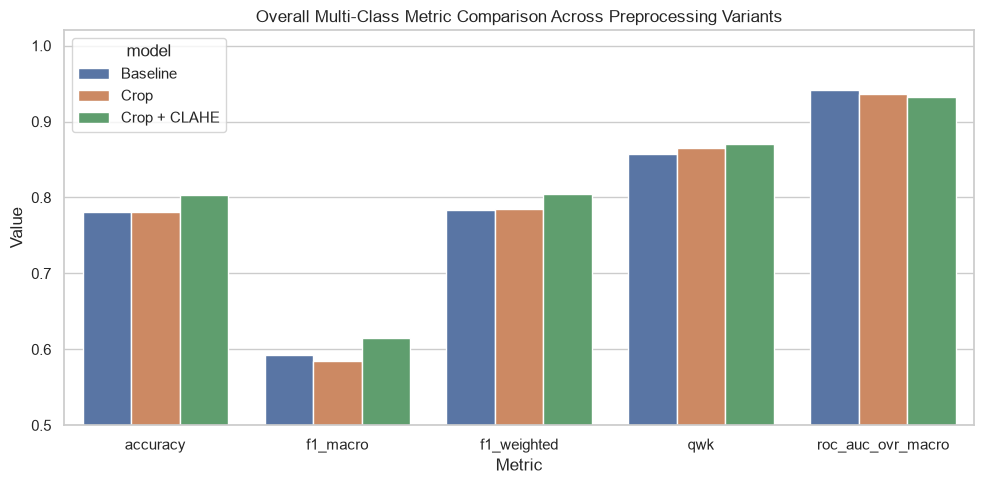

In [8]:
plot_metric_names = ["accuracy", "f1_macro", "f1_weighted", "qwk", "roc_auc_ovr_macro"]
plot_df = metrics_comparison_df.loc[metrics_comparison_df["metric"].isin(plot_metric_names)].melt(
    id_vars="metric",
    value_vars=[spec["column_name"] for spec in model_specs],
    var_name="model",
    value_name="value",
)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=plot_df, x="metric", y="value", hue="model", ax=ax)
ax.set_title("Overall Multi-Class Metric Comparison Across Preprocessing Variants")
ax.set_xlabel("Metric")
ax.set_ylabel("Value")
ax.set_ylim(0.5, 1.02)
plt.tight_layout()
fig.savefig(comparison_dir / "figure_12_1_multiclass_preprocessing_metric_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


**Figure 12.2. Per-class F1-score comparison across the three EfficientNet-B0 multi-class preprocessing experiments**


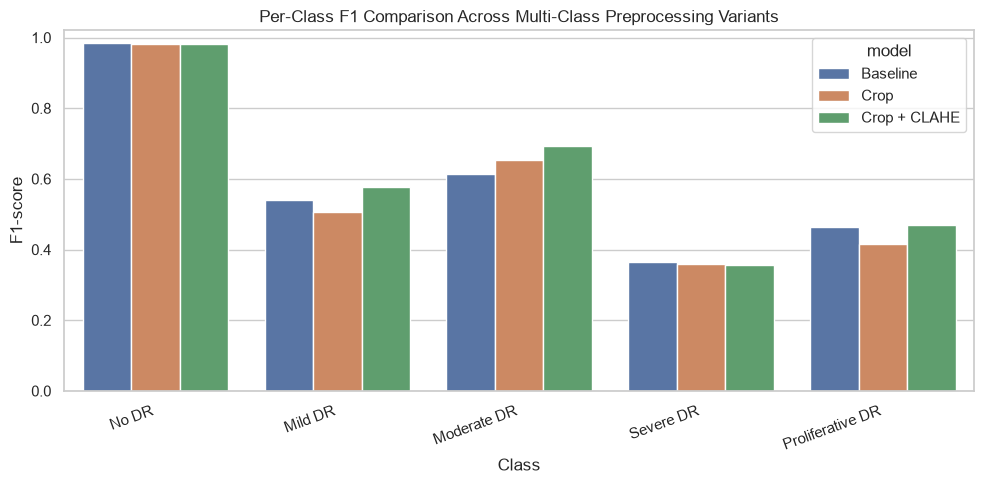

In [9]:
plot_df = per_class_f1_df.melt(
    id_vars=["class_id", "class_name"],
    value_vars=[spec["column_name"] for spec in model_specs],
    var_name="model",
    value_name="f1_score",
)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=plot_df, x="class_name", y="f1_score", hue="model", ax=ax)
ax.set_title("Per-Class F1 Comparison Across Multi-Class Preprocessing Variants")
ax.set_xlabel("Class")
ax.set_ylabel("F1-score")
ax.set_ylim(0, 1.02)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
fig.savefig(comparison_dir / "figure_12_2_multiclass_preprocessing_per_class_f1.png", dpi=300, bbox_inches="tight")
plt.show()


**Figure 12.3. Rare-class recall comparison for Severe DR and Proliferative DR across preprocessing variants**


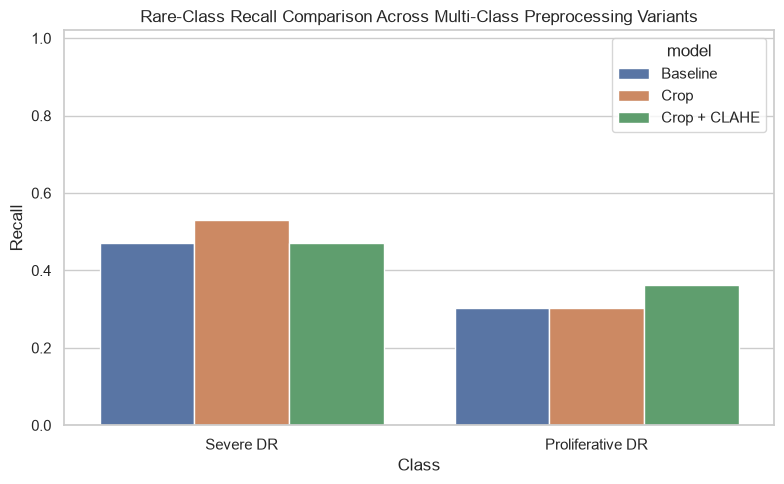

In [10]:
plot_df = rare_class_recall_df.melt(
    id_vars="class_name",
    value_vars=[spec["column_name"] for spec in model_specs],
    var_name="model",
    value_name="recall",
)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=plot_df, x="class_name", y="recall", hue="model", ax=ax)
ax.set_title("Rare-Class Recall Comparison Across Multi-Class Preprocessing Variants")
ax.set_xlabel("Class")
ax.set_ylabel("Recall")
ax.set_ylim(0, 1.02)
plt.tight_layout()
fig.savefig(comparison_dir / "figure_12_3_multiclass_preprocessing_rare_class_recall.png", dpi=300, bbox_inches="tight")
plt.show()
